# 02 · Error analysis: `gpu_ablation_effnet_b0`

Inputs come from `python -m src.evaluate` (`results/gpu_ablation_effnet_b0/`). Goal: understand *which* dishes fail, *why*, and *what a mistake costs* in calories.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
ROOT = os.path.abspath('..'); EXP = 'gpu_ablation_effnet_b0'
R = f'{ROOT}/results/{EXP}'
IMG_ROOT = f'{ROOT}/data/cache/food101_256'
metrics = json.load(open(f'{R}/metrics.json')); metrics

{'experiment': 'gpu_ablation_effnet_b0',
 'backbone': 'efficientnet_b0',
 'split': 'test',
 'num_images': 25250,
 'num_classes': 101,
 'top1': 0.8346138613861386,
 'top5': 0.9642376237623762,
 'macro_f1': 0.8330500837373089,
 'params_m': 4.14,
 'cpu_latency_ms': 22.0}

## Per-class F1: hardest and easiest dishes

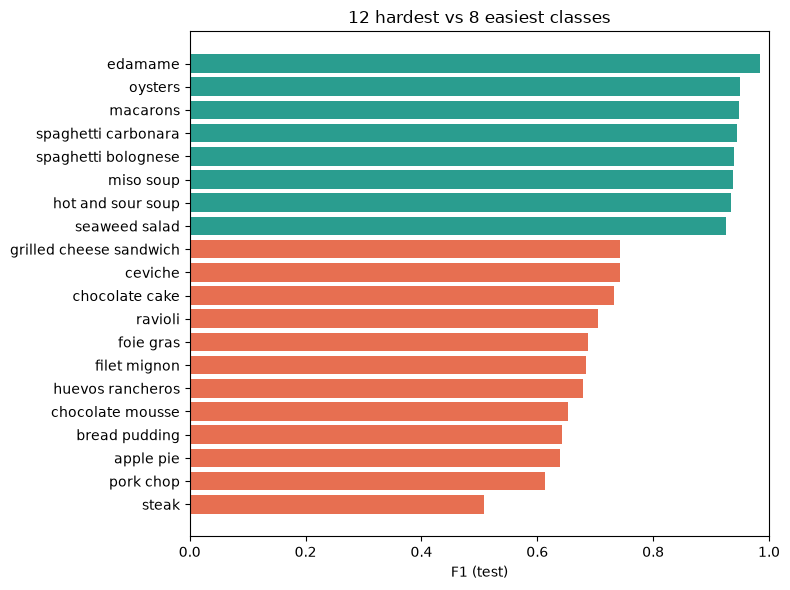

,class,precision,recall,f1,support
0,steak,0.5405,0.480,0.5085,250
1,pork_chop,0.6240,0.604,0.6138,250
2,apple_pie,0.7727,0.544,0.6385,250
3,bread_pudding,0.7122,0.584,0.6418,250
4,chocolate_mousse,0.6937,0.616,0.6525,250
5,huevos_rancheros,0.7884,0.596,0.6788,250
6,filet_mignon,0.6389,0.736,0.6840,250
7,foie_gras,0.6679,0.708,0.6874,250
8,ravioli,0.7628,0.656,0.7054,250
9,chocolate_cake,0.7048,0.764,0.7332,250


In [2]:
pc = pd.read_csv(f'{R}/per_class.csv').sort_values('f1')
show = pd.concat([pc.head(12), pc.tail(8)])
plt.figure(figsize=(8, 6))
plt.barh(show['class'].str.replace('_',' '), show.f1, color=['#e76f51']*12 + ['#2a9d8f']*8)
plt.xlabel('F1 (test)'); plt.title('12 hardest vs 8 easiest classes'); plt.xlim(0, 1); plt.tight_layout()
plt.savefig(f'{ROOT}/assets/per_class_f1.png', dpi=100); plt.show()
pc.head(12)

## Most-confused pairs (true → predicted)

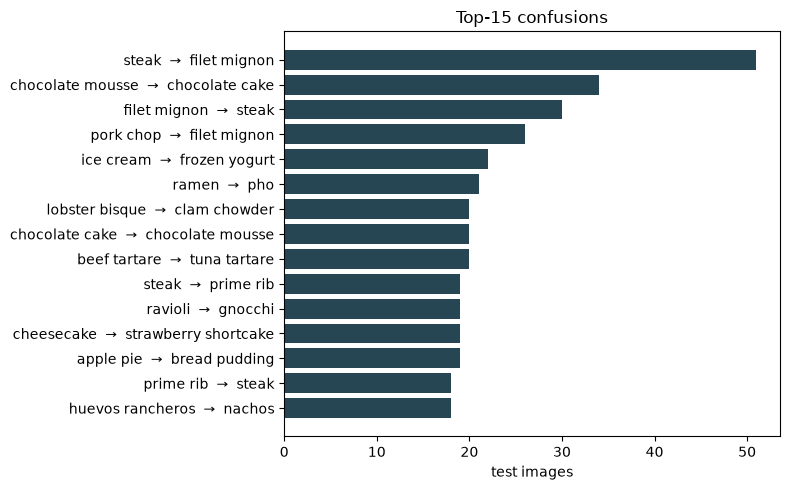

,true,predicted,count,rate_of_true_class
0,steak,filet_mignon,51,0.204
1,chocolate_mousse,chocolate_cake,34,0.136
2,filet_mignon,steak,30,0.120
3,pork_chop,filet_mignon,26,0.104
4,ice_cream,frozen_yogurt,22,0.088
5,ramen,pho,21,0.084
6,lobster_bisque,clam_chowder,20,0.080
7,chocolate_cake,chocolate_mousse,20,0.080
8,beef_tartare,tuna_tartare,20,0.080
9,steak,prime_rib,19,0.076


In [3]:
cp = pd.read_csv(f'{R}/confused_pairs.csv').head(15)
lab = cp.true.str.replace('_',' ') + '  →  ' + cp.predicted.str.replace('_',' ')
plt.figure(figsize=(8, 5)); plt.barh(lab[::-1], cp['count'][::-1], color='#264653')
plt.xlabel('test images'); plt.title('Top-15 confusions'); plt.tight_layout()
plt.savefig(f'{ROOT}/assets/confused_pairs.png', dpi=100); plt.show()
cp

## Confidence: is the model's confidence meaningful?
The app warns when top-1 confidence < 0.4. This checks that low confidence really does flag likely errors, and how much a user-correction step recovers (true label inside the top-3 shown to the user).

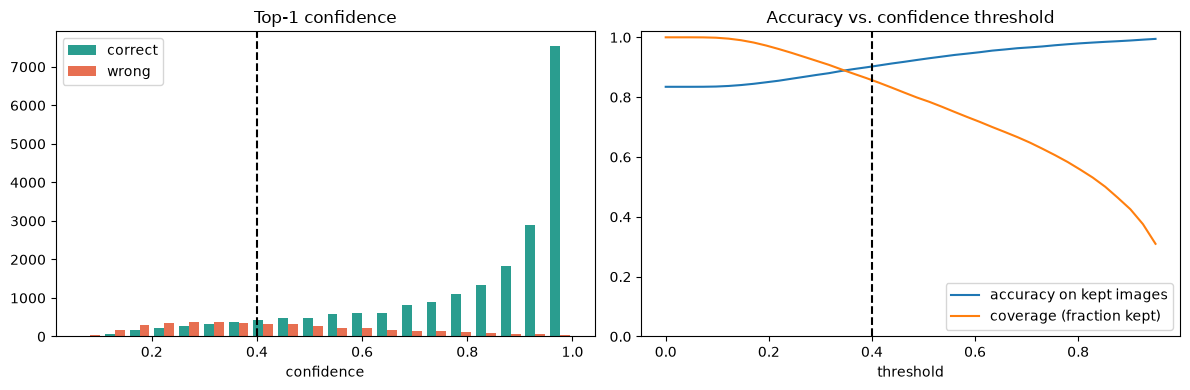

top-1 0.835 | top-3 0.940
images flagged low-confidence: 14.3%; accuracy flagged 0.427 vs not flagged 0.903
errors recoverable by picking from the top-3 list: 63.7%


In [4]:
pr = pd.read_csv(f'{R}/predictions.csv')
pr['top3'] = pr.top5.str.split('|').apply(lambda xs: [x.split(':')[0] for x in xs[:3]])
pr['in_top3'] = [t in s for t, s in zip(pr.true, pr.top3)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist([pr.conf[pr.correct == 1], pr.conf[pr.correct == 0]], bins=20, label=['correct', 'wrong'], color=['#2a9d8f', '#e76f51'])
ax[0].axvline(0.4, ls='--', c='k'); ax[0].set(title='Top-1 confidence', xlabel='confidence'); ax[0].legend()
th = np.linspace(0, 0.95, 40)
ax[1].plot(th, [pr.correct[pr.conf >= t].mean() for t in th], label='accuracy on kept images')
ax[1].plot(th, [(pr.conf >= t).mean() for t in th], label='coverage (fraction kept)')
ax[1].axvline(0.4, ls='--', c='k'); ax[1].set(title='Accuracy vs. confidence threshold', xlabel='threshold', ylim=(0, 1.02)); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{ROOT}/assets/confidence.png', dpi=100); plt.show()
low = pr.conf < 0.4
print(f"top-1 {pr.correct.mean():.3f} | top-3 {pr.in_top3.mean():.3f}")
print(f"images flagged low-confidence: {low.mean():.1%}; accuracy flagged {pr.correct[low].mean():.3f} vs not flagged {pr.correct[~low].mean():.3f}")
print(f"errors recoverable by picking from the top-3 list: {pr.in_top3[pr.correct == 0].mean():.1%}")

## What does a mistake cost in calories?
For every misclassified image: |kcal(predicted dish) − kcal(true dish)| for one typical serving of the true dish's weight. Confusing two similar cakes is cheap; confusing a salad with a cake is not.

In [5]:
from src.nutrition import load_db
db = load_db()
err = pr[pr.correct == 0].copy()
err['kcal_true'] = [db.estimate(t, db.get(t).serving_g).kcal for t in err.true]
err['kcal_pred'] = [db.estimate(p, db.get(t).serving_g).kcal for p, t in zip(err.pred, err.true)]
err['abs_err'] = (err.kcal_pred - err.kcal_true).abs()
err['rel_err'] = err.abs_err / err.kcal_true
print(err[['abs_err', 'rel_err']].describe(percentiles=[.5, .9]).round(2))
print(f"\nmisclassifications costing <20% kcal error: {(err.rel_err < 0.2).mean():.1%}")
worst = err.groupby(['true', 'pred']).agg(n=('abs_err', 'size'), kcal_err=('abs_err', 'mean')).query('n >= 2').sort_values('kcal_err', ascending=False).head(10)
worst.round(0)

       abs_err  rel_err
count  4176.00  4176.00
mean    128.85     0.49
std     117.98     0.65
min       0.00     0.00
50%      97.50     0.33
90%     295.00     0.93
max    1752.00     9.74

misclassifications costing <20% kcal error: 31.1%


,,n,kcal_err
true,pred,,
sushi,baklava,2,623.0
lasagna,carrot_cake,2,588.0
french_onion_soup,grilled_cheese_sandwich,2,576.0
lasagna,garlic_bread,2,525.0
fish_and_chips,onion_rings,2,506.0
cheesecake,creme_brulee,2,500.0
bibimbap,croque_madame,3,496.0
cheesecake,frozen_yogurt,2,476.0
sushi,cup_cakes,2,464.0


## Failure gallery: the most confident mistakes
Each pair: the photo with Grad-CAM for the **wrong** predicted class, then Grad-CAM for the **true** class.

C:\Users\ASUS\nutrisnap\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


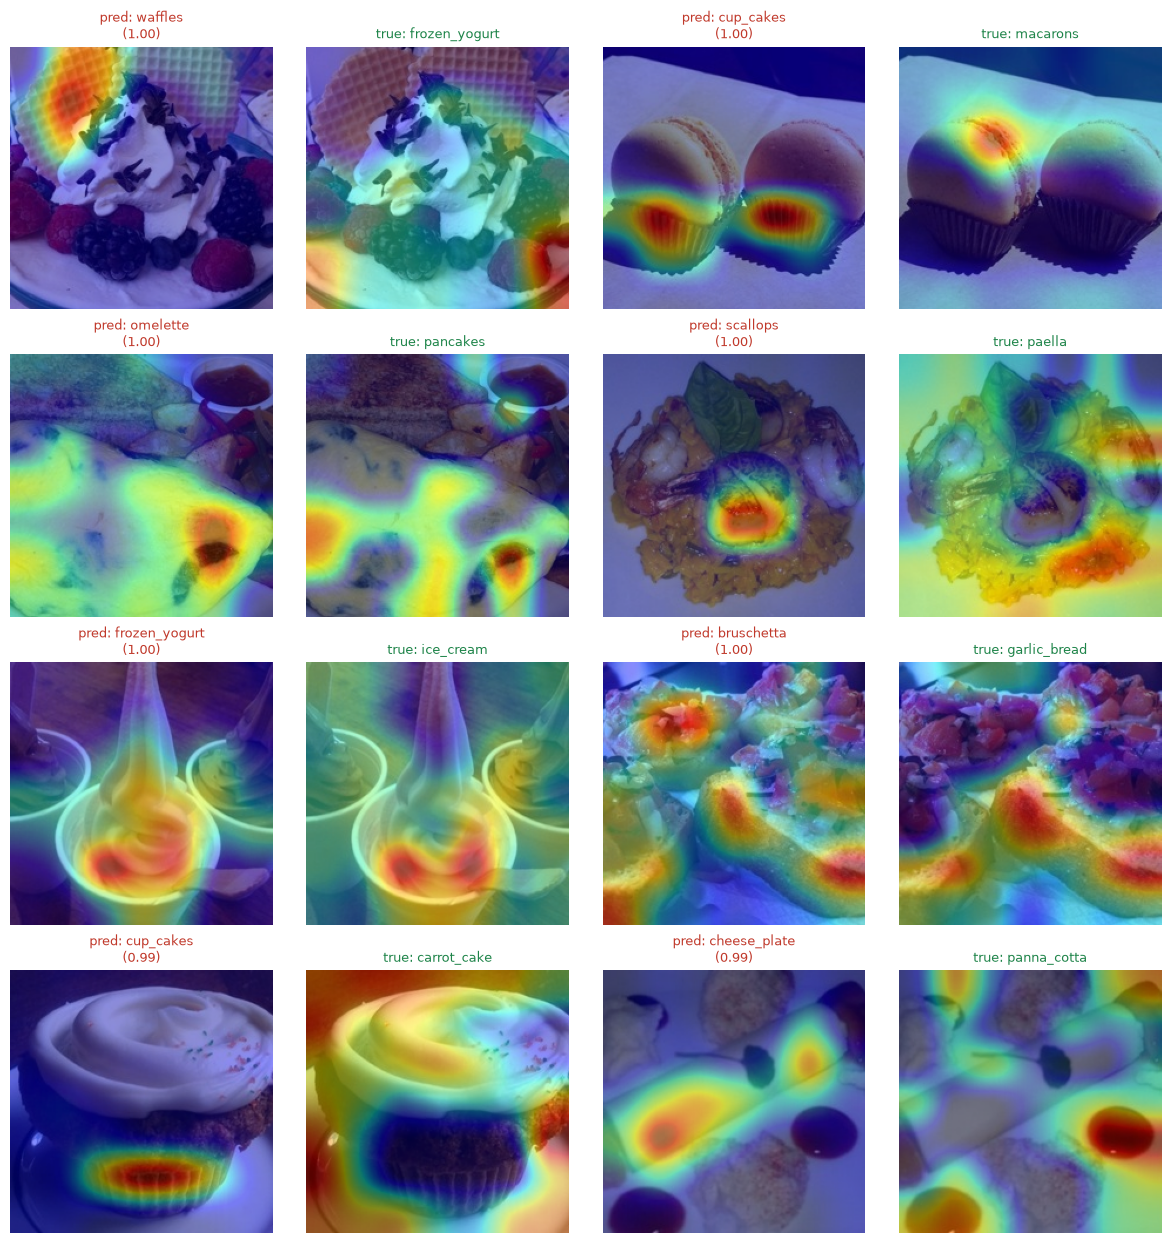

In [6]:
from src.predict import Predictor
ckpt = f'{ROOT}/checkpoints/{EXP}/best.pt'
P = Predictor(ckpt, tta=False)
wrong = pr[pr.correct == 0].sort_values('conf', ascending=False).head(8)
fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for (_, r), ax2 in zip(wrong.iterrows(), axes.reshape(-1, 2)):
    img = Image.open(f'{IMG_ROOT}/{r.path}').convert('RGB')
    ax2[0].imshow(P.explain(img, r.pred)); ax2[0].set_title(f'pred: {r.pred}\n({r.conf:.2f})', fontsize=9, color='#c0392b')
    ax2[1].imshow(P.explain(img, r.true)); ax2[1].set_title(f'true: {r.true}', fontsize=9, color='#1e8449')
    for a in ax2: a.axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/assets/failure_cases.jpg', dpi=80); plt.show()

## Notes: why these fail

_Write your observations here after reviewing the outputs above (see 02_error_analysis.ipynb for an example)._